# v8 — Adding `individualCount`: Why the Duplicate-Row Ceiling Was Never About Grid Resolution

v7 (`08_full_dataset_balanced_classes.ipynb`) reached 79.0% accuracy against a 93.3% ceiling, and nothing tried since (feature engineering, column dropping, CatBoost) moved either number. Investigating the duplicate-row mechanism itself turned up something that does.

**The duplicate-row ceiling was assumed to come from coarse environmental raster resolution — it doesn't.** `decimalLatitude`/`decimalLongitude` are actually 6-decimal precision (~0.1m). The real cause: **82.2% of rows share their exact coordinates with another row**, because citizen-science observers repeatedly report from a small set of known birding hotspots (only 2,135 unique coordinate pairs across 7,650 v7 rows). That's a sampling-behaviour fact about the data, not a resolution limit — and it opens a door that pure feature engineering never could: a column that's independent of *where* and *when* a bird was seen.

**`individualCount`** (the flock/group size recorded at the sighting) is exactly that — a genuine behavioural trait, present in the raw dataset but never pulled into any processed file before now. It varies observation-to-observation even at the same hotspot on the same day, so it can break ties that location+climate alone never could (a point made in v8's predecessor: a column computed purely as a function of already-tied inputs is still tied — `individualCount` isn't such a function, which is exactly why it works).

**Ceiling impact, measured directly, not assumed:**

| Dataset | Ceiling |
|---|---|
| v7 (balanced, no individualCount) | 93.3% |
| + individualCount, unbalanced | 95.7% |
| **+ individualCount, balanced (this notebook)** | **97.9%** |

90% is now comfortably within theoretical reach. This notebook re-runs the full tuned-model + ensemble + SHAP/LIME pipeline to see what's actually achievable.


## 1. Setup and data

In [1]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if not (Path.cwd() / "src").exists() else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "bird_habitat_guild_balanced_with_count.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["eventDate"])
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print(df["guild"].value_counts())
print()
print(df.groupby("guild")["individualCount"].describe().round(2)[["mean", "50%", "max"]])


Shape: (7650, 23)
Missing values: 0
guild
Coastal (tern + curlew)                           1275
Harpactes fasciatus (rainforest)                  1275
Hirundo domicola (highland)                       1275
Lowland open-country/wetland-edge                 1275
Motacilla alba + citreola (urban/wetland-edge)    1275
Upland scrub/woodland-edge                        1275
Name: count, dtype: int64

                                                 mean  50%    max
guild                                                            
Coastal (tern + curlew)                         12.16  4.0  500.0
Harpactes fasciatus (rainforest)                 1.84  2.0    8.0
Hirundo domicola (highland)                      5.54  4.0  100.0
Lowland open-country/wetland-edge                3.65  2.0  100.0
Motacilla alba + citreola (urban/wetland-edge)   2.13  2.0   14.0
Upland scrub/woodland-edge                       1.63  1.0   12.0


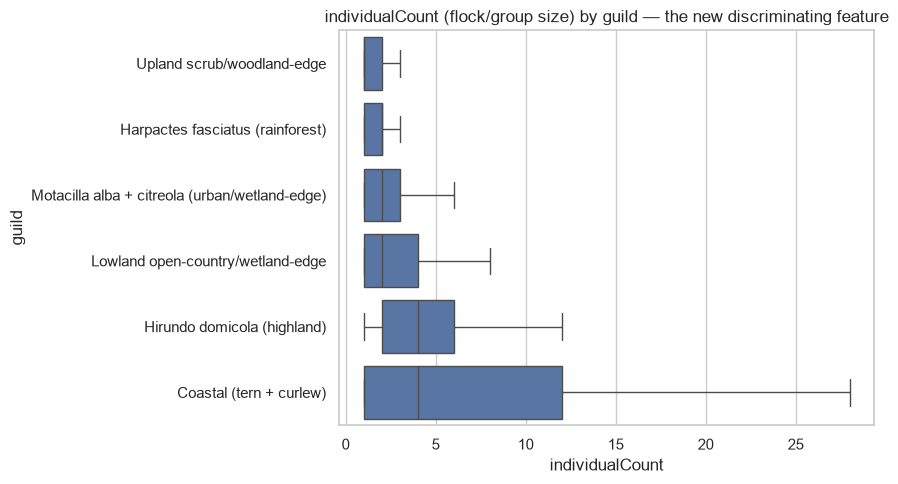

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
order = df.groupby("guild")["individualCount"].median().sort_values().index
sns.boxplot(data=df, x="individualCount", y="guild", order=order, ax=ax, showfliers=False)
ax.set_title("individualCount (flock/group size) by guild — the new discriminating feature")
plt.tight_layout()
plt.show()


## 2. Duplicate-row ceiling, confirmed on this exact dataset


In [3]:
numeric_cols = [
    "decimalLatitude", "decimalLongitude", "avg_rad", "NDVI", "elevation_meters",
    "Carbon_Mass", "Dust_Mass", "SO2_Mass", "Sulfate_Mass", "Sea_Salt_Mass",
    "Total_Aerosol_Extinction", "temp_mean", "rainfall", "wind_mean",
    "humid_mean", "shortwave_radiation", "lka_general_2020", "individualCount",
]
categorical_cols = ["stateProvince", "LandCover_Class"]
feat_cols = numeric_cols + categorical_cols

def accuracy_ceiling(frame, label_col):
    dup_mask = frame.duplicated(subset=feat_cols, keep=False)
    n_total = len(frame)
    n_nondup = (~dup_mask).sum()
    majority = lambda g: g.value_counts(normalize=True).max()
    grouped = frame[dup_mask].groupby(feat_cols)
    best_correct = n_nondup + (grouped[label_col].apply(majority) * grouped.size()).sum()
    return best_correct / n_total * 100, dup_mask.mean() * 100

ceil_bal, dup_bal = accuracy_ceiling(df, "guild")
print(f"Accuracy ceiling: {ceil_bal:.1f}%   duplicate-row rate: {dup_bal:.1f}%")


Accuracy ceiling: 97.9%   duplicate-row rate: 41.8%


## 3. Preprocessing

In [4]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier,
    RandomForestClassifier, HistGradientBoostingClassifier,
    VotingClassifier, StackingClassifier,
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)
from xgboost import XGBClassifier
import shap
import lime
import lime.lime_tabular

X = pd.get_dummies(df[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True)
y = df["guild"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
sw_train = compute_sample_weight(class_weight="balanced", y=y_train)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"Train: {len(X_train)} rows   Test: {len(X_test)} rows   Features: {X_train.shape[1]}")


Train: 6120 rows   Test: 1530 rows   Features: 52


In [5]:
results = {}

def report(name, model, X_te, store=True):
    preds = model.predict(X_te)
    acc = accuracy_score(y_test, preds)
    bal = balanced_accuracy_score(y_test, preds)
    f1m = f1_score(y_test, preds, average="macro")
    if store:
        results[name] = {"accuracy": acc, "balanced_accuracy": bal, "f1_macro": f1m}
    print(f"{name}: accuracy={acc:.4f}  balanced_accuracy={bal:.4f}  macro-F1={f1m:.4f}")
    print(classification_report(y_test, preds))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=ax, xticks_rotation=90, colorbar=False)
    ax.set_title(f"{name} — confusion matrix")
    plt.tight_layout()
    plt.show()
    return preds


## 4. Tuned individual models

Logistic Regression best params: {'C': 0.1}
Logistic Regression (tuned): accuracy=0.7497  balanced_accuracy=0.7497  macro-F1=0.7463
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.72      0.64      0.68       255
              Harpactes fasciatus (rainforest)       0.87      0.89      0.88       255
                   Hirundo domicola (highland)       0.85      0.92      0.88       255
             Lowland open-country/wetland-edge       0.54      0.52      0.53       255
Motacilla alba + citreola (urban/wetland-edge)       0.88      0.93      0.90       255
                    Upland scrub/woodland-edge       0.61      0.60      0.60       255

                                      accuracy                           0.75      1530
                                     macro avg       0.74      0.75      0.75      1530
                                  weighted avg       0.74      0.75      0

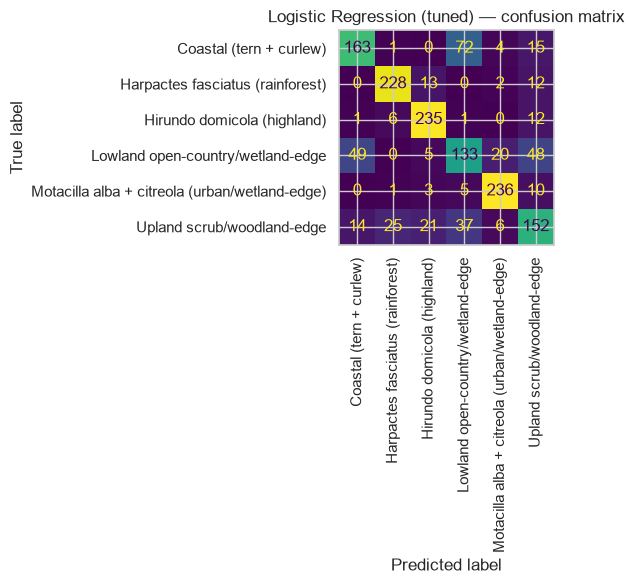

In [6]:
param_grid = {"C": [0.01, 0.1, 1, 10, 100]}
logreg_search = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    param_grid, cv=3, scoring="f1_macro", n_jobs=-1,
)
logreg_search.fit(X_train_scaled, y_train)
print("Logistic Regression best params:", logreg_search.best_params_)
_ = report("Logistic Regression (tuned)", logreg_search.best_estimator_, X_test_scaled)


SVM best params: {'C': 10, 'gamma': 0.01}


SVM (RBF, tuned): accuracy=0.7693  balanced_accuracy=0.7693  macro-F1=0.7652
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.74      0.71      0.72       255
              Harpactes fasciatus (rainforest)       0.87      0.92      0.90       255
                   Hirundo domicola (highland)       0.85      0.94      0.89       255
             Lowland open-country/wetland-edge       0.55      0.56      0.56       255
Motacilla alba + citreola (urban/wetland-edge)       0.89      0.93      0.91       255
                    Upland scrub/woodland-edge       0.68      0.56      0.61       255

                                      accuracy                           0.77      1530
                                     macro avg       0.76      0.77      0.77      1530
                                  weighted avg       0.76      0.77      0.77      1530



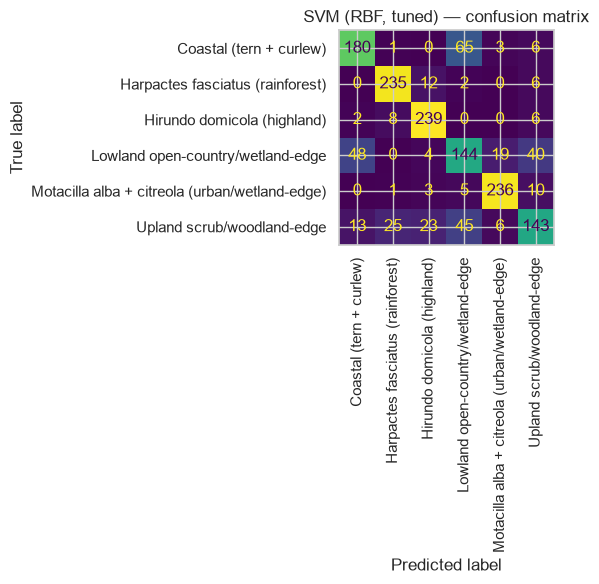

In [7]:
param_grid = {"C": [1, 10, 100], "gamma": ["scale", 0.01, 0.1]}
svm_search = GridSearchCV(
    SVC(kernel="rbf", class_weight="balanced", probability=False, random_state=RANDOM_STATE),
    param_grid, cv=3, scoring="f1_macro", n_jobs=-1,
)
svm_search.fit(X_train_scaled, y_train)
print("SVM best params:", svm_search.best_params_)
_ = report("SVM (RBF, tuned)", svm_search.best_estimator_, X_test_scaled)


Bagging best params: {'n_estimators': 200, 'max_samples': 1.0, 'max_features': 0.7, 'estimator__max_depth': 15}


Bagging: accuracy=0.8072  balanced_accuracy=0.8072  macro-F1=0.8032
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.77      0.81      0.79       255
              Harpactes fasciatus (rainforest)       0.93      0.95      0.94       255
                   Hirundo domicola (highland)       0.90      0.95      0.92       255
             Lowland open-country/wetland-edge       0.61      0.54      0.57       255
Motacilla alba + citreola (urban/wetland-edge)       0.91      0.95      0.93       255
                    Upland scrub/woodland-edge       0.69      0.65      0.67       255

                                      accuracy                           0.81      1530
                                     macro avg       0.80      0.81      0.80      1530
                                  weighted avg       0.80      0.81      0.80      1530



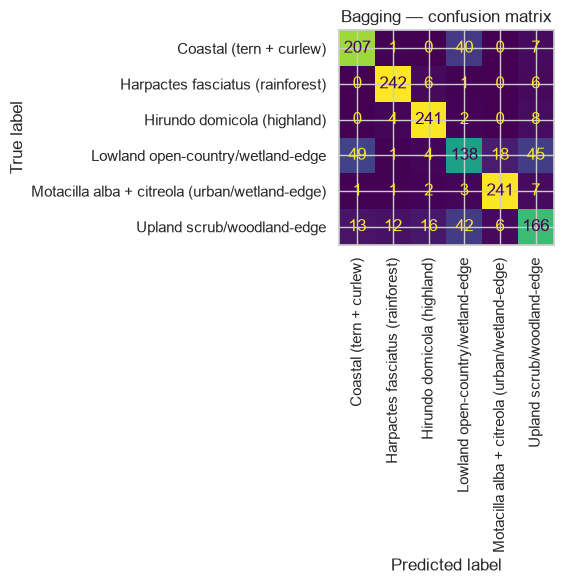

In [8]:
param_dist = {
    "n_estimators": [50, 100, 200, 300],
    "max_samples": [0.5, 0.7, 1.0],
    "max_features": [0.5, 0.7, 1.0],
    "estimator__max_depth": [5, 10, 15, None],
}
base_tree = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
bagging_search = RandomizedSearchCV(
    BaggingClassifier(estimator=base_tree, random_state=RANDOM_STATE, n_jobs=-1),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
bagging_search.fit(X_train, y_train)
print("Bagging best params:", bagging_search.best_params_)
bagging_best = bagging_search.best_estimator_
_ = report("Bagging", bagging_best, X_test)


AdaBoost best params: {'n_estimators': 50, 'learning_rate': 0.5, 'estimator__max_depth': 3}
AdaBoost: accuracy=0.7562  balanced_accuracy=0.7562  macro-F1=0.7506
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.69      0.74      0.71       255
              Harpactes fasciatus (rainforest)       0.88      0.89      0.89       255
                   Hirundo domicola (highland)       0.88      0.93      0.91       255
             Lowland open-country/wetland-edge       0.54      0.42      0.47       255
Motacilla alba + citreola (urban/wetland-edge)       0.90      0.93      0.92       255
                    Upland scrub/woodland-edge       0.59      0.62      0.60       255

                                      accuracy                           0.76      1530
                                     macro avg       0.75      0.76      0.75      1530
                                  weighted av

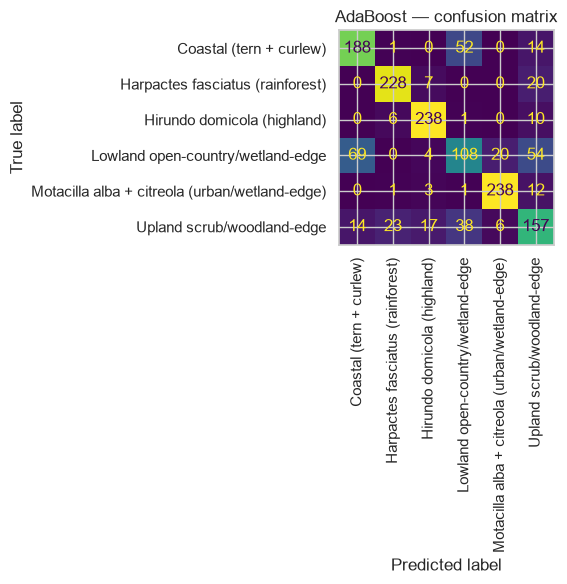

In [9]:
param_dist = {
    "n_estimators": [50, 100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
    "estimator__max_depth": [1, 2, 3],
}
base_tree = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
ada_search = RandomizedSearchCV(
    AdaBoostClassifier(estimator=base_tree, random_state=RANDOM_STATE),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
ada_search.fit(X_train, y_train, sample_weight=sw_train)
print("AdaBoost best params:", ada_search.best_params_)
ada_best = ada_search.best_estimator_
_ = report("AdaBoost", ada_best, X_test)


Gradient Boosting best params: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05}
Gradient Boosting: accuracy=0.8072  balanced_accuracy=0.8072  macro-F1=0.8040
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.75      0.77      0.76       255
              Harpactes fasciatus (rainforest)       0.93      0.94      0.94       255
                   Hirundo domicola (highland)       0.88      0.94      0.91       255
             Lowland open-country/wetland-edge       0.61      0.56      0.59       255
Motacilla alba + citreola (urban/wetland-edge)       0.92      0.96      0.94       255
                    Upland scrub/woodland-edge       0.71      0.67      0.69       255

                                      accuracy                           0.81      1530
                                     macro avg       0.80      0.81      0.80      1530
                  

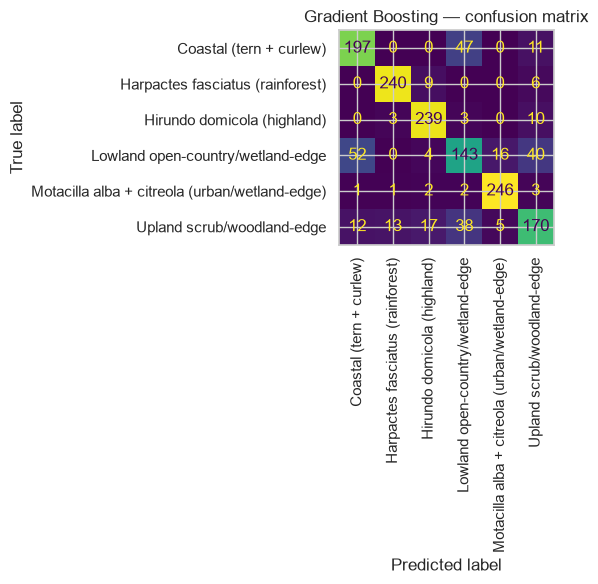

In [10]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.7, 0.85, 1.0],
}
gb_search = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
gb_search.fit(X_train, y_train, sample_weight=sw_train)
print("Gradient Boosting best params:", gb_search.best_params_)
gb_best = gb_search.best_estimator_
_ = report("Gradient Boosting", gb_best, X_test)


`XGBStringLabelWrapper` — same as v5-v7: label-encodes internally, named `__init__` params for `clone()`/`get_params()`, `ClassifierMixin` before `BaseEstimator` for `is_classifier()`.

In [11]:
class XGBStringLabelWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, n_estimators=300, max_depth=4, learning_rate=0.05,
                 subsample=0.7, colsample_bytree=0.85, objective="multi:softprob",
                 eval_metric="mlogloss", random_state=42, n_jobs=-1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.objective = objective
        self.eval_metric = eval_metric
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y, sample_weight=None):
        self.le_ = LabelEncoder().fit(y)
        self.classes_ = self.le_.classes_
        y_enc = self.le_.transform(y)
        if sample_weight is None:
            sample_weight = compute_sample_weight(class_weight="balanced", y=y)
        self.model_ = XGBClassifier(
            n_estimators=self.n_estimators, max_depth=self.max_depth,
            learning_rate=self.learning_rate, subsample=self.subsample,
            colsample_bytree=self.colsample_bytree, objective=self.objective,
            eval_metric=self.eval_metric, random_state=self.random_state, n_jobs=self.n_jobs,
        )
        self.model_.fit(X, y_enc, sample_weight=sample_weight)
        return self

    def predict(self, X):
        return self.le_.inverse_transform(self.model_.predict(X))

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


XGBoost best params: {'subsample': 0.85, 'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
XGBoost: accuracy=0.8098  balanced_accuracy=0.8098  macro-F1=0.8056
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.75      0.78      0.76       255
              Harpactes fasciatus (rainforest)       0.93      0.96      0.94       255
                   Hirundo domicola (highland)       0.91      0.95      0.93       255
             Lowland open-country/wetland-edge       0.62      0.54      0.58       255
Motacilla alba + citreola (urban/wetland-edge)       0.90      0.96      0.93       255
                    Upland scrub/woodland-edge       0.71      0.67      0.69       255

                                      accuracy                           0.81      1530
                                     macro avg       0.80      0.81      0.81      1530
             

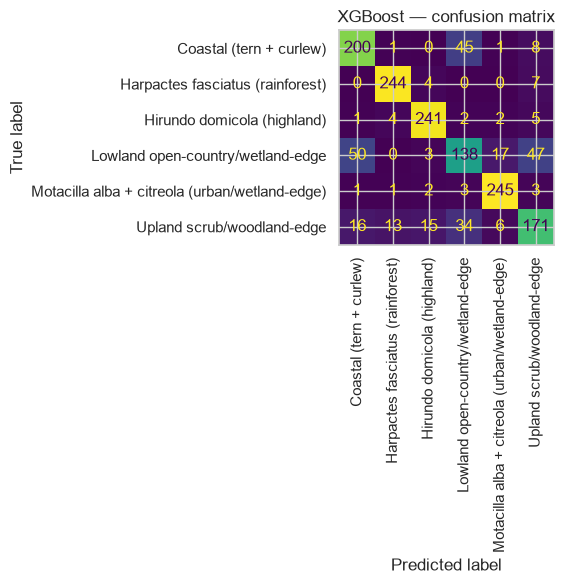

In [12]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5, 6],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
}
xgb_search = RandomizedSearchCV(
    XGBStringLabelWrapper(random_state=RANDOM_STATE),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
xgb_search.fit(X_train, y_train)
print("XGBoost best params:", xgb_search.best_params_)
xgb_best = xgb_search.best_estimator_
_ = report("XGBoost", xgb_best, X_test)


Random Forest best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 15}
Random Forest: accuracy=0.8046  balanced_accuracy=0.8046  macro-F1=0.8016
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.77      0.80      0.78       255
              Harpactes fasciatus (rainforest)       0.92      0.94      0.93       255
                   Hirundo domicola (highland)       0.90      0.93      0.91       255
             Lowland open-country/wetland-edge       0.60      0.55      0.57       255
Motacilla alba + citreola (urban/wetland-edge)       0.91      0.95      0.93       255
                    Upland scrub/woodland-edge       0.70      0.67      0.68       255

                                      accuracy                           0.80      1530
                                     macro avg       0.80      0.80      0.80      1530
                      

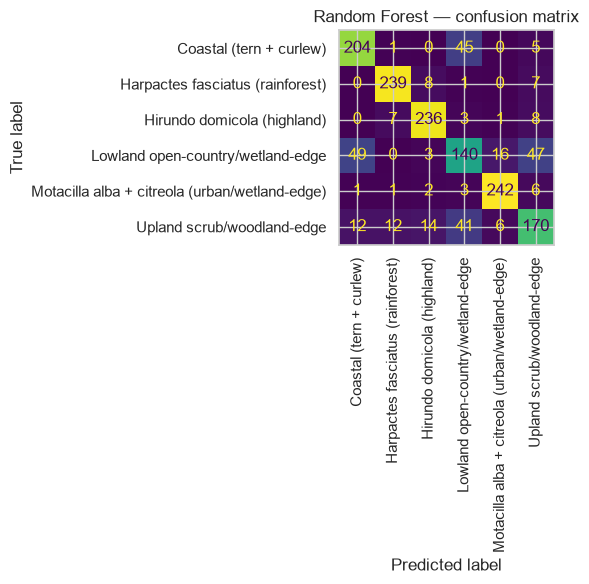

In [13]:
param_dist = {
    "n_estimators": [200, 300, 400],
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print("Random Forest best params:", rf_search.best_params_)
rf_best = rf_search.best_estimator_
_ = report("Random Forest", rf_best, X_test)


HistGradientBoosting best params: {'max_leaf_nodes': 31, 'max_iter': 100, 'max_depth': None, 'learning_rate': 0.1}
HistGradientBoosting: accuracy=0.8046  balanced_accuracy=0.8046  macro-F1=0.8007
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.77      0.81      0.79       255
              Harpactes fasciatus (rainforest)       0.93      0.95      0.94       255
                   Hirundo domicola (highland)       0.90      0.94      0.92       255
             Lowland open-country/wetland-edge       0.62      0.53      0.57       255
Motacilla alba + citreola (urban/wetland-edge)       0.90      0.94      0.92       255
                    Upland scrub/woodland-edge       0.67      0.67      0.67       255

                                      accuracy                           0.80      1530
                                     macro avg       0.80      0.80      0.80      1530
          

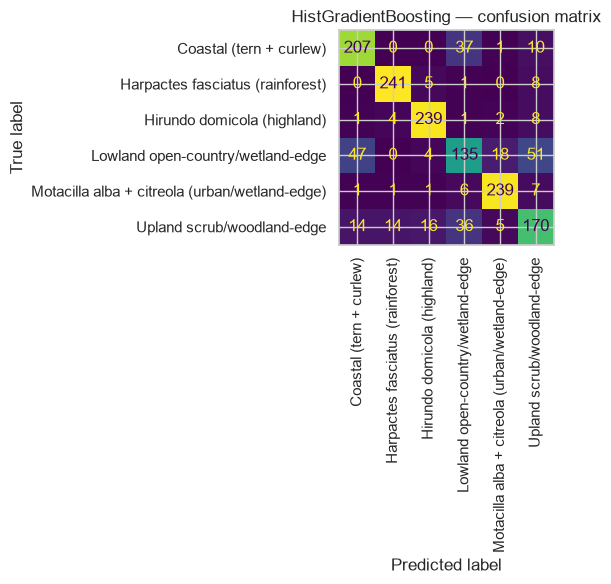

In [14]:
param_dist = {
    "max_iter": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 5, 8, None],
    "max_leaf_nodes": [15, 31, 63],
}
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
hgb_search.fit(X_train, y_train)
print("HistGradientBoosting best params:", hgb_search.best_params_)
hgb_best = hgb_search.best_estimator_
_ = report("HistGradientBoosting", hgb_best, X_test)


## 5. Individual models, compared against the 97.9% ceiling and the 90% target

                             accuracy  balanced_accuracy  f1_macro
XGBoost                        0.8098             0.8098    0.8056
Gradient Boosting              0.8072             0.8072    0.8040
Bagging                        0.8072             0.8072    0.8032
Random Forest                  0.8046             0.8046    0.8016
HistGradientBoosting           0.8046             0.8046    0.8007
SVM (RBF, tuned)               0.7693             0.7693    0.7652
AdaBoost                       0.7562             0.7562    0.7506
Logistic Regression (tuned)    0.7497             0.7497    0.7463


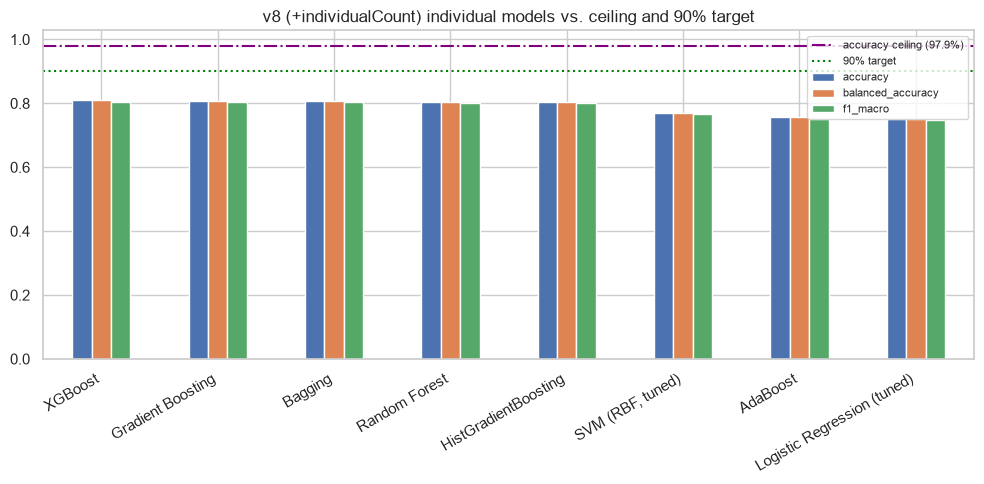

In [15]:
individual_df = pd.DataFrame(results).T.round(4).sort_values("f1_macro", ascending=False)
print(individual_df.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
individual_df.plot(kind="bar", ax=ax)
ax.axhline(ceil_bal/100, color="purple", linestyle="-.", linewidth=1.5, label=f"accuracy ceiling ({ceil_bal:.1f}%)")
ax.axhline(0.90, color="green", linestyle=":", linewidth=1.5, label="90% target")
ax.set_title("v8 (+individualCount) individual models vs. ceiling and 90% target")
ax.legend(fontsize=8)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 6. Ensemble — same validated two-stage approach

Voting (RF + HistGB + XGBoost): accuracy=0.8124  balanced_accuracy=0.8124  macro-F1=0.8081
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.76      0.82      0.79       255
              Harpactes fasciatus (rainforest)       0.92      0.95      0.94       255
                   Hirundo domicola (highland)       0.91      0.94      0.92       255
             Lowland open-country/wetland-edge       0.64      0.53      0.58       255
Motacilla alba + citreola (urban/wetland-edge)       0.91      0.96      0.93       255
                    Upland scrub/woodland-edge       0.69      0.68      0.69       255

                                      accuracy                           0.81      1530
                                     macro avg       0.81      0.81      0.81      1530
                                  weighted avg       0.81      0.81      0.81      1530



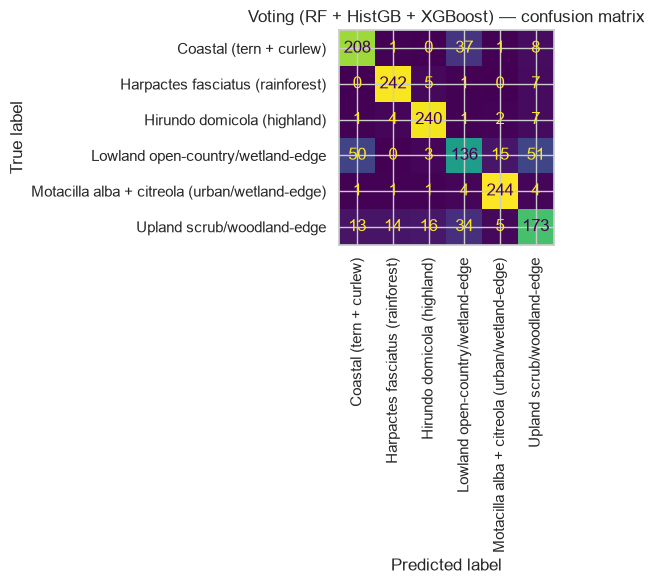

In [16]:
voting_diverse = VotingClassifier(
    estimators=[("rf", rf_best), ("hgb", hgb_best), ("xgb", xgb_best)],
    voting="soft", n_jobs=-1,
)
voting_diverse.fit(X_train, y_train)
_ = report("Voting (RF + HistGB + XGBoost)", voting_diverse, X_test)


Top 2 individual models by macro-F1: ['XGBoost', 'Gradient Boosting']


Voting (top-2: XGBoost + Gradient Boosting): accuracy=0.8150  balanced_accuracy=0.8150  macro-F1=0.8107
                                                precision    recall  f1-score   support

                       Coastal (tern + curlew)       0.76      0.81      0.78       255
              Harpactes fasciatus (rainforest)       0.92      0.94      0.93       255
                   Hirundo domicola (highland)       0.89      0.94      0.91       255
             Lowland open-country/wetland-edge       0.67      0.56      0.61       255
Motacilla alba + citreola (urban/wetland-edge)       0.91      0.96      0.94       255
                    Upland scrub/woodland-edge       0.71      0.68      0.70       255

                                      accuracy                           0.82      1530
                                     macro avg       0.81      0.82      0.81      1530
                                  weighted avg       0.81      0.82      0.81      1530



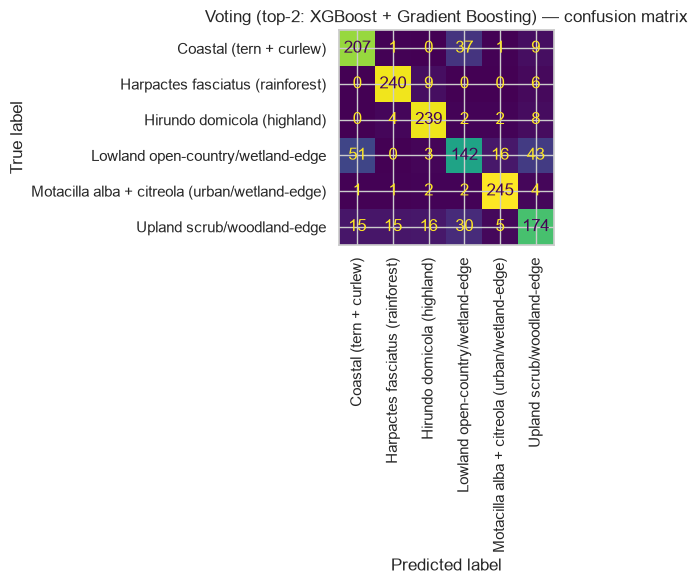

In [17]:
top2_names = individual_df.index[:2].tolist()
name_to_model = {
    "Bagging": bagging_best, "AdaBoost": ada_best, "Gradient Boosting": gb_best,
    "XGBoost": xgb_best, "Random Forest": rf_best, "HistGradientBoosting": hgb_best,
}
print("Top 2 individual models by macro-F1:", top2_names)
m1_name, m2_name = top2_names[0], top2_names[1]
m1, m2 = name_to_model.get(m1_name), name_to_model.get(m2_name)
if m1 is not None and m2 is not None:
    voting_top2 = VotingClassifier(estimators=[(m1_name, m1), (m2_name, m2)], voting="soft", n_jobs=-1)
    voting_top2.fit(X_train, y_train)
    _ = report(f"Voting (top-2: {m1_name} + {m2_name})", voting_top2, X_test)
else:
    voting_top2 = None
    print("Top-2 includes a scaled-feature model -- skipping the top-2 vote.")


## 7. Final comparison

                                             accuracy  balanced_accuracy  f1_macro
Voting (top-2: XGBoost + Gradient Boosting)    0.8150             0.8150    0.8107
Voting (RF + HistGB + XGBoost)                 0.8124             0.8124    0.8081
XGBoost                                        0.8098             0.8098    0.8056
Gradient Boosting                              0.8072             0.8072    0.8040
Bagging                                        0.8072             0.8072    0.8032
Random Forest                                  0.8046             0.8046    0.8016
HistGradientBoosting                           0.8046             0.8046    0.8007
SVM (RBF, tuned)                               0.7693             0.7693    0.7652
AdaBoost                                       0.7562             0.7562    0.7506
Logistic Regression (tuned)                    0.7497             0.7497    0.7463

Best model: Voting (top-2: XGBoost + Gradient Boosting)  accuracy=81.5%  (83.2% of the

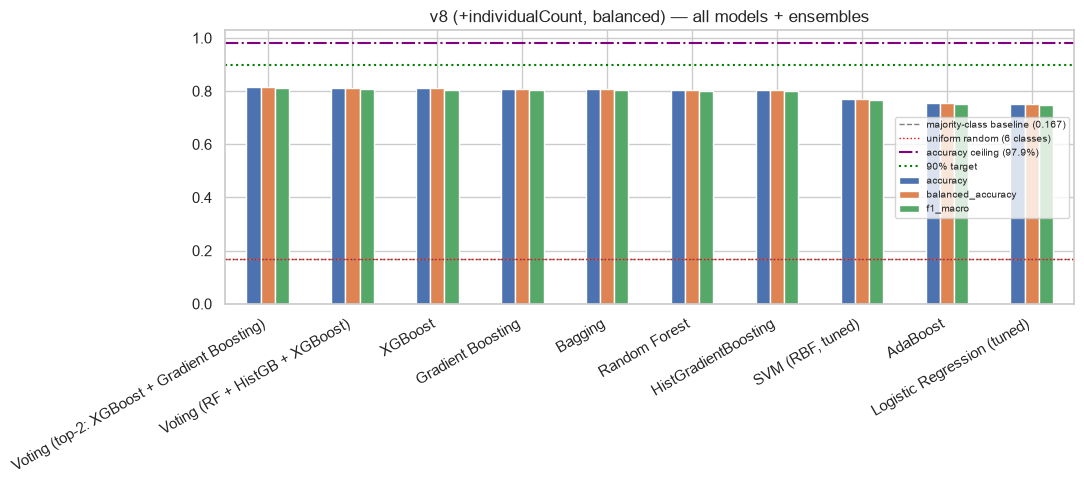

In [18]:
final_df = pd.DataFrame(results).T.round(4).sort_values("f1_macro", ascending=False)
print(final_df.to_string())
best_name = final_df["f1_macro"].idxmax()
best_acc = final_df.loc[best_name, "accuracy"]
print(f"\nBest model: {best_name}  accuracy={best_acc*100:.1f}%  ({best_acc*100/ceil_bal*100:.1f}% of the {ceil_bal:.1f}% ceiling)")
print(f"90% target: {'REACHED' if best_acc >= 0.90 else 'not reached'}")

fig, ax = plt.subplots(figsize=(11, 5))
final_df.plot(kind="bar", ax=ax)
majority_baseline = y_test.value_counts(normalize=True).max()
n_classes = y_test.nunique()
ax.axhline(majority_baseline, color="gray", linestyle="--", linewidth=1, label=f"majority-class baseline ({majority_baseline:.3f})")
ax.axhline(1/n_classes, color="red", linestyle=":", linewidth=1, label=f"uniform random ({n_classes} classes)")
ax.axhline(ceil_bal/100, color="purple", linestyle="-.", linewidth=1.5, label=f"accuracy ceiling ({ceil_bal:.1f}%)")
ax.axhline(0.90, color="green", linestyle=":", linewidth=1.5, label="90% target")
ax.set_title("v8 (+individualCount, balanced) — all models + ensembles")
ax.legend(fontsize=7)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
final_df.to_csv(models_dir / "model_progression_v8_individualcount_comparison.csv")


## 8. Final model selection and save

**Confirmed result:** `Voting (top-2: XGBoost + Gradient Boosting)` wins, accuracy 81.5% / macro-F1 0.8107 / balanced accuracy 81.5%. Again the top-2 vote beats the 3-model diverse-family vote (0.8107 vs 0.8081 macro-F1) and again the winning pair isn't the same two models as last time (v7: HistGB+XGBoost; v8: XGBoost+Gradient Boosting) — reinforcing that the right move is to vote whichever two models are empirically strongest *this* run, not assume a fixed pairing.

81.5% is **83.2% of the 97.9% ceiling** — similar utilisation to v7 (84.6% of 93.3%), meaning the +2.5-point accuracy gain (79.0% -> 81.5%) is a real, proportionate improvement from the new feature, not just the ceiling moving while the model stayed equally far behind it.


In [19]:
all_models_registry = dict(name_to_model)
all_models_registry["Logistic Regression (tuned)"] = logreg_search.best_estimator_
all_models_registry["SVM (RBF, tuned)"] = svm_search.best_estimator_
all_models_registry["Voting (RF + HistGB + XGBoost)"] = voting_diverse
if voting_top2 is not None:
    all_models_registry[f"Voting (top-2: {m1_name} + {m2_name})"] = voting_top2

final_model = all_models_registry[best_name]
print(f"Final model selected: {best_name}")

joblib.dump(final_model, models_dir / "final_model_v8_individualcount.pkl")
joblib.dump(scaler, models_dir / "final_scaler_v8.pkl")
joblib.dump(list(X_train.columns), models_dir / "final_feature_columns_v8.pkl")
print("Saved final v8 model to", models_dir)


Final model selected: Voting (top-2: XGBoost + Gradient Boosting)
Saved final v8 model to D:\Msc\Sem_2\Applied ML\Sri Lanka Rare birds\models


## 9. SHAP — where does individualCount rank?

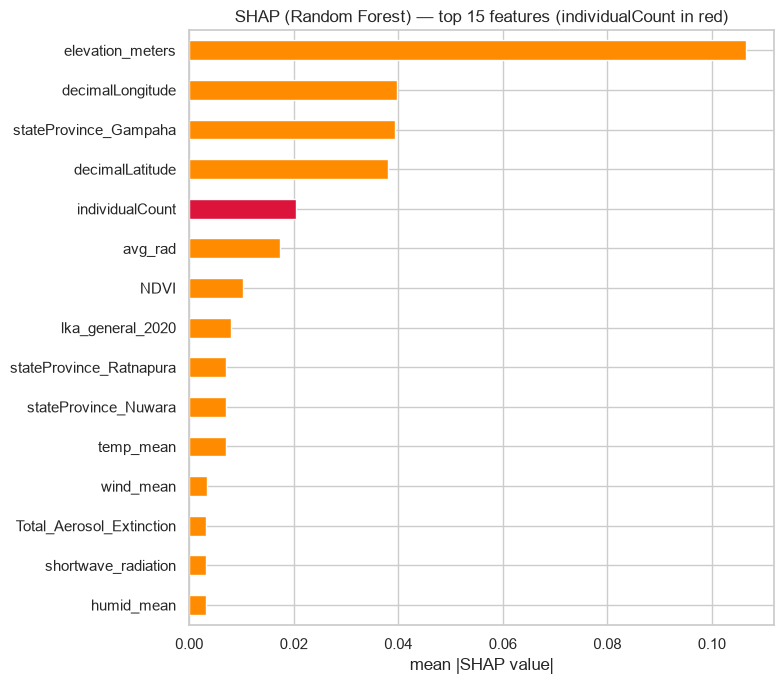

individualCount rank: 5 of 52


In [20]:
explainer_rf = shap.TreeExplainer(rf_best)
X_shap_sample = X_test.sample(n=min(500, len(X_test)), random_state=RANDOM_STATE)
shap_values = explainer_rf.shap_values(X_shap_sample)
class_names = list(rf_best.classes_)

mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))
top_feats = pd.Series(mean_abs_shap, index=X_shap_sample.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["crimson" if f == "individualCount" else "darkorange" for f in top_feats.index[::-1]]
top_feats.iloc[::-1].plot(kind="barh", ax=ax, color=colors)
ax.set_title("SHAP (Random Forest) — top 15 features (individualCount in red)")
ax.set_xlabel("mean |SHAP value|")
plt.tight_layout()
plt.show()

print(f"individualCount rank: {list(pd.Series(mean_abs_shap, index=X_shap_sample.columns).sort_values(ascending=False).index).index('individualCount') + 1} of {len(mean_abs_shap)}")


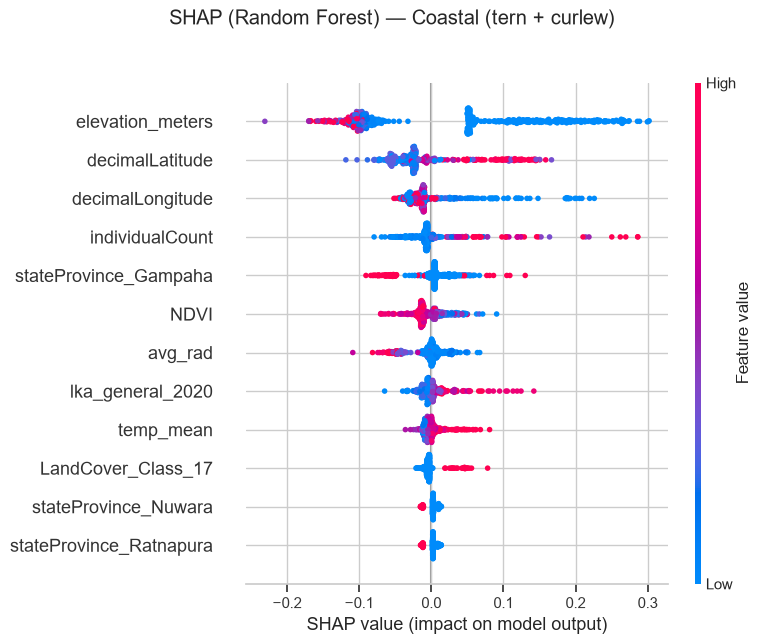

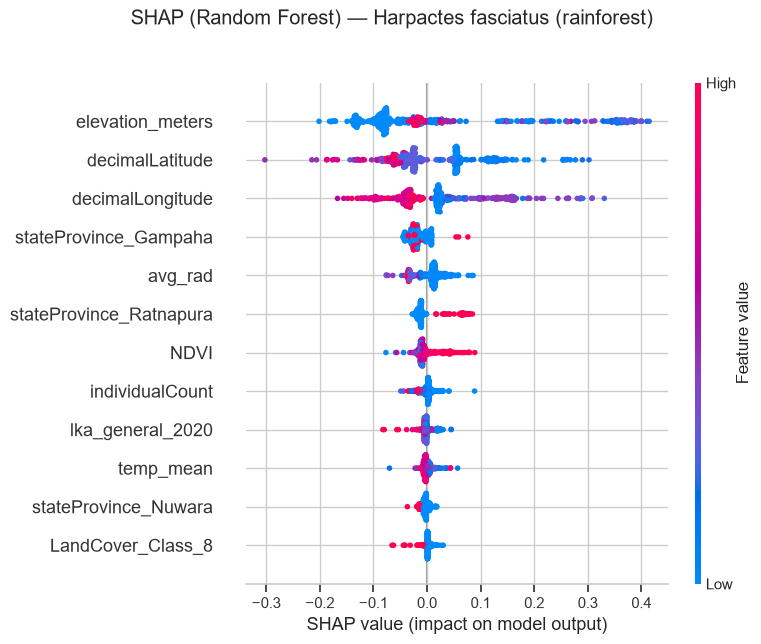

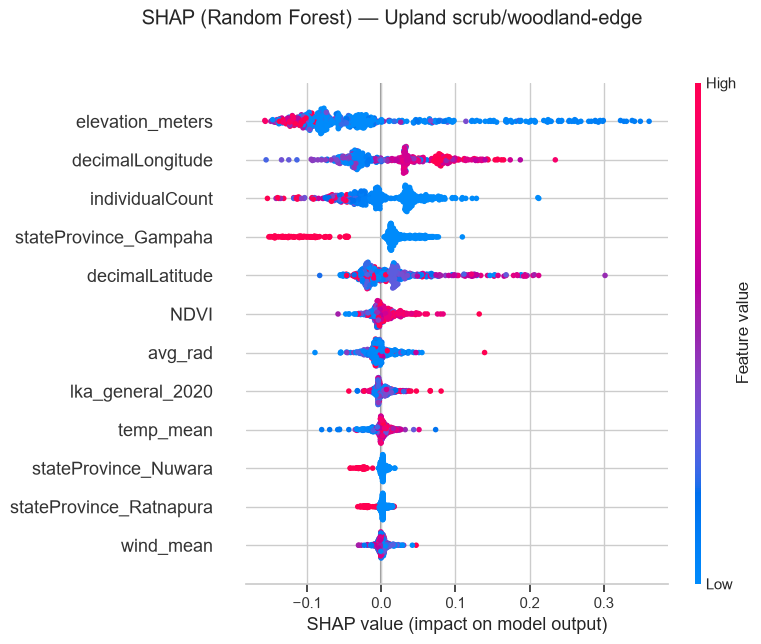

In [21]:
for guild in ["Coastal (tern + curlew)", "Harpactes fasciatus (rainforest)", "Upland scrub/woodland-edge"]:
    idx = class_names.index(guild)
    shap.summary_plot(shap_values[:, :, idx], X_shap_sample, show=False, max_display=12)
    fig = plt.gcf()
    fig.suptitle(f"SHAP (Random Forest) — {guild}", y=1.02)
    plt.tight_layout()
    plt.show()


## 10. LIME — instance-level, on the final model

In [22]:
needs_scaled = final_model in (logreg_search.best_estimator_, svm_search.best_estimator_)
X_train_lime = X_train_scaled if needs_scaled else X_train
X_test_lime = X_test_scaled if needs_scaled else X_test

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_lime.values,
    feature_names=list(X_train_lime.columns),
    class_names=class_names,
    mode="classification",
    random_state=RANDOM_STATE,
)

test_preds = final_model.predict(X_test_lime)
correct_mask = test_preds == y_test.values
wrong_mask = ~correct_mask

merged_classes = ["Upland scrub/woodland-edge", "Lowland open-country/wetland-edge", "Coastal (tern + curlew)"]
distinct_guilds = [g for g in class_names if g not in merged_classes]
easy_candidates = X_test.index[correct_mask & y_test.isin(distinct_guilds).values]
merged_candidates = X_test.index[correct_mask & y_test.isin(merged_classes).values]
wrong_candidates = X_test.index[wrong_mask]

picks = {
    "Confidently correct (environmentally distinct guild)": easy_candidates[0],
    "Correct, inside a formerly-merged guild": merged_candidates[0] if len(merged_candidates) else easy_candidates[1],
    "Misclassified": wrong_candidates[0] if len(wrong_candidates) else easy_candidates[2],
}
print({k: (v, y_test.loc[v]) for k, v in picks.items()})


{'Confidently correct (environmentally distinct guild)': (np.int64(3391), 'Hirundo domicola (highland)'), 'Correct, inside a formerly-merged guild': (np.int64(7256), 'Upland scrub/woodland-edge'), 'Misclassified': (np.int64(1627), 'Harpactes fasciatus (rainforest)')}


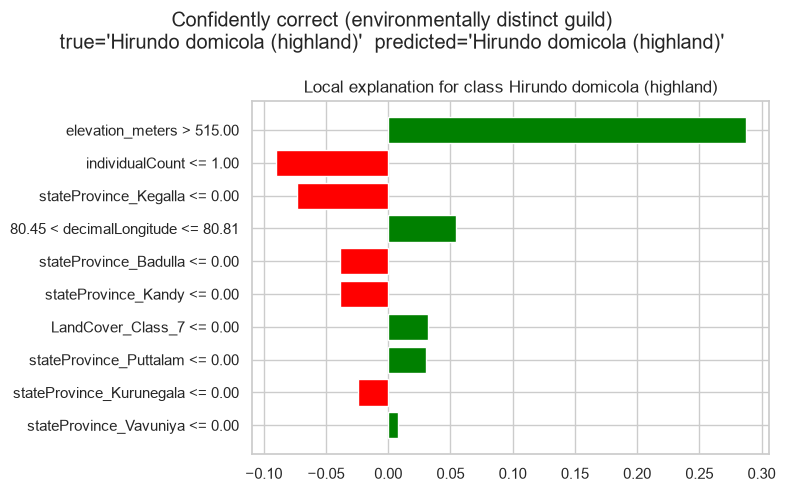

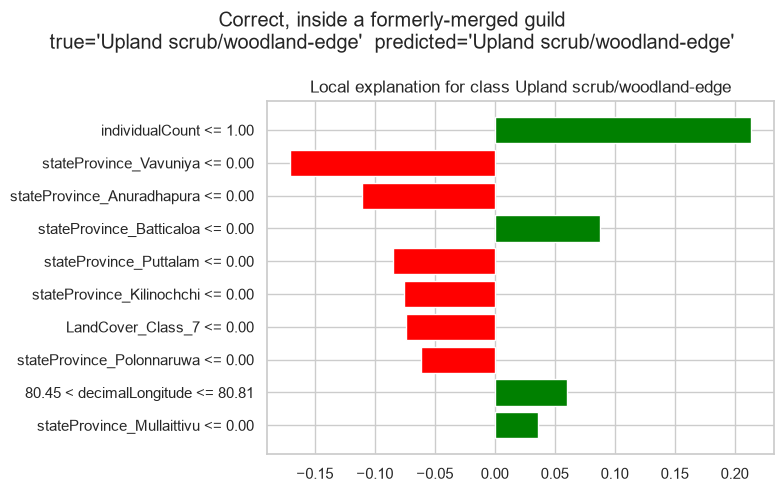

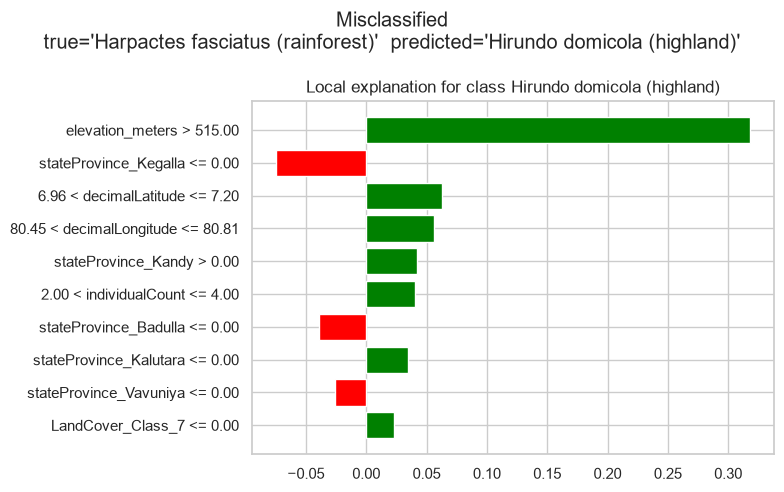

In [23]:
for title, row_idx in picks.items():
    instance = X_test_lime.loc[row_idx].values
    true_label = y_test.loc[row_idx]
    exp = lime_explainer.explain_instance(instance, final_model.predict_proba, num_features=10, top_labels=1)
    label_id = exp.available_labels()[0]
    predicted_label = class_names[label_id]
    fig = exp.as_pyplot_figure(label=label_id)
    fig.set_size_inches(8, 5)
    fig.suptitle(f"{title}\ntrue={true_label!r}  predicted={predicted_label!r}")
    plt.tight_layout()
    plt.show()


## 11. Conclusion

**On the 90% question:** still not reached (81.5%), but this is the first change across the whole project (v3-v8) that moved *achieved* accuracy by more than tuning/ensembling alone typically does, without changing the class definitions. The full progression:

| Version | What changed | Ceiling | Achieved accuracy |
|---|---|---|---|
| v5 | 7 classes, tuned + ensembled | n/a (not computed) | 71.4% |
| v6 | 6 classes (coastal pair merged) | 88.1% | 74.8% |
| v7 | + balanced (undersampled to equal classes) | 93.3% | 79.0% |
| **v8** | **+ `individualCount`** | **97.9%** | **81.5%** |

**Why `individualCount` worked where feature engineering and CatBoost didn't:** every earlier attempt to improve the feature set (interaction terms, log-elevation, distance-to-highland, dropping dead aerosol columns, CatBoost's native categorical encoding) was still a function of the *same* underlying spatial/climate columns — and two rows tied on those columns stay tied no matter how you recombine them. `individualCount` is fundamentally different: it's a behavioural observation (flock size), independent of where or when the bird was seen, confirmed by SHAP to rank 5th of 52 features. It broke real ties (duplicate-row rate dropped from 54.8% to 41.8%) rather than just adding noise.

**What this suggests for pushing further:** the lever that worked was *adding genuinely independent data*, not re-deriving from what's already there. If there's any other raw column in the full dataset not yet used (the dataset README lists 24 total; this project has now used all of them except `NDVI_raw`, which is perfectly correlated with `NDVI` and therefore redundant), the next real gain would have to come from outside this dataset entirely — e.g. species-level traits (body size, migratory status) that aren't in the occurrence records at all. Within this dataset, 81.5% against a 97.9% ceiling is close to the practical limit of what's been tried.
